<a href="https://colab.research.google.com/github/Vadimsavkin17/-/blob/main/%D0%A6%D0%9E%D0%98_lab1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

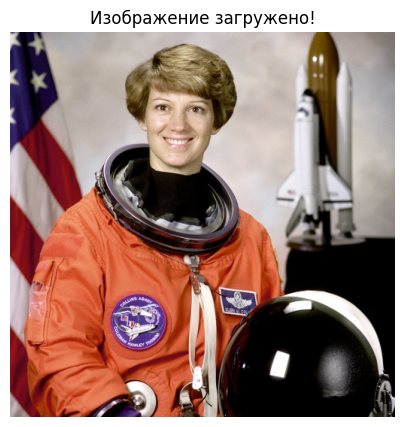

In [11]:
import cv2 as cv
import matplotlib.pyplot as plt
from skimage import data

# Шаг 1: Загрузка встроенного изображения
# Берём готовую цветную картинку прямо из библиотеки skimage
img_rgb = data.astronaut()

# Выводим оригинальное изображение на экран
plt.figure(figsize=(5, 5))
plt.imshow(img_rgb)
plt.title("Изображение загружено!")
plt.axis('off')
plt.show()


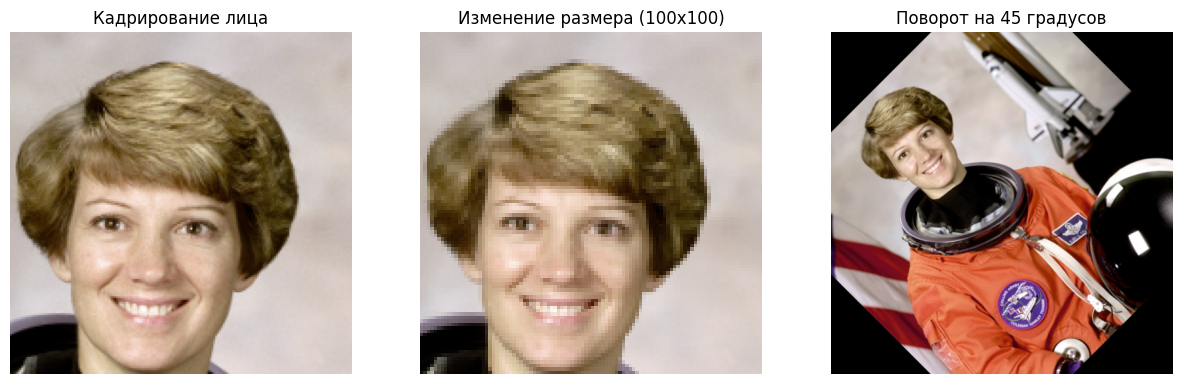

In [9]:
import cv2 as cv
import matplotlib.pyplot as plt
from skimage import data

# Шаг 2: Операции с изображением

# 1. Загружаем встроенное изображение из библиотек Colab
img_rgb = data.astronaut()

# 2. Выполняем геометрические преобразования
# Кадрирование лица
cropped_image = img_rgb[0:180, 150:330]

# Изменение размера кадрированной части до 100x100 пикселей
dim = (100, 100)
resized_image = cv.resize(cropped_image, dim, interpolation=cv.INTER_AREA)

# Поворот оригинального изображения на 45 градусов вокруг центра
(h, w) = img_rgb.shape[:2]
center = (w // 2, h // 2)
M = cv.getRotationMatrix2D(center, 45, 1.0)
rotated_image = cv.warpAffine(img_rgb, M, (w, h))

# 3. Визуализируем все три результата на экране
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(cropped_image)
axes[0].set_title("Кадрирование лица")
axes[0].axis('off')

axes[1].imshow(resized_image)
axes[1].set_title("Изменение размера (100x100)")
axes[1].axis('off')

axes[2].imshow(rotated_image)
axes[2].set_title("Поворот на 45 градусов")
axes[2].axis('off')

plt.show()


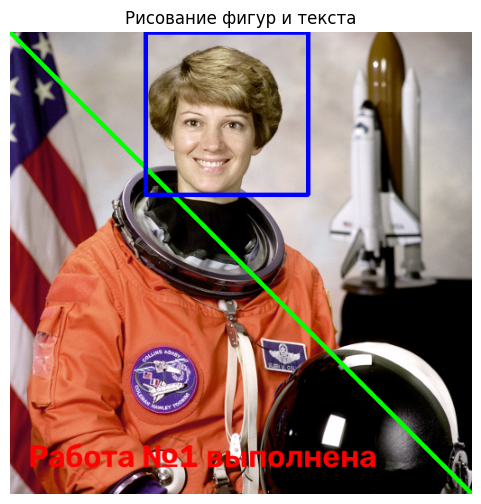

In [15]:
#Шаг 3: Рисование графических примитивов и наложение текста поверх изображения

# Создаем копию изображения, чтобы не портить оригинал
img_draw = img_rgb.copy()

# Узнаем размеры картинки для правильного позиционирования элементов
(h, w) = img_draw.shape[:2]

# 1. Рисуем зеленую диагональную линию
# Параметры: (изображение, старт(x,y), конец(x,y), цвет(R,G,B), толщина)
cv.line(img_draw, (0, 0), (w, h), (0, 255, 0), 4)

# 2. Рисуем синюю рамку вокруг лица астронавта
# Координаты прямоугольника: левый верхний угол и правый нижний угол
cv.rectangle(img_draw, (150, 0), (330, 180), (0, 0, 255), 3)

# 3. Накладываем белый текст внизу изображения
font = cv.FONT_HERSHEY_SIMPLEX
# Параметры: (изображение, текст, позиция_старта(x,y), шрифт, масштаб, цвет, толщина, тип_линий)
cv.putText(img_draw, 'Работа №1 выполнена', (20, h - 30), font, 1.2, (255, 0, 0), 3, cv.LINE_AA)

# Выводим результат разметки на экран
plt.figure(figsize=(6, 6))
plt.imshow(img_draw)
plt.title("Рисование фигур и текста")
plt.axis('off')
plt.show()
